# Numerical EDA

Explores asking rent, missingness, distributions, correlations and time patterns.

**Data:** synthetic
**Inputs:** `data/master_listing.parquet` and `data/master_columns.csv`.
**Outputs:** `outputs/synthetic/05_phase_01_edav_summary`.
**Run after:** 03_numerical_selection and 04_numerical_correlations.

In [1]:
# ---- Data ----
INPUT = "data/master_listing.parquet"   # relative to the repo root

# ---- Filters (None = no filter) ----
CITY = None             # "chicago", "dfw", "dc", or a list of them       -> column `market`
NEIGHBORHOOD = None     # submarket or list -> `market_building__submarket`
START_DATE = None       # "YYYY-MM-DD": keep listings with DATE_COLUMN >= START_DATE
END_DATE = None         # "YYYY-MM-DD": keep listings with DATE_COLUMN <= END_DATE
DATE_COLUMN = "market_unit__enter_market"

# ---- EDAV ----
TARGET = "market_price_observation__first_asking_rent"
SAMPLE_N = 200_000      # rows sampled for plots and per-variable stats; None = all rows
SEED = 710
TOP_N = 6               # variables shown in the boxplot and rent-vs-variable grids
NOT_IN_TOP = ["market_building__lat", "market_building__lon"]   # coordinates mostly identify the city

In [2]:
from pathlib import Path
import sys

import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "libs").is_dir())
sys.path.insert(0, str(ROOT))   # lets the notebook import the shared libs/ package

from libs import paths
from libs.console import done, note, step
from libs.notebook import Run, need
from libs.plots import style_axes, variable_label

MASTER = ROOT / INPUT
CATALOG = paths.CATALOG
OUTPUTS = paths.output_dir("synthetic")
NN = 5
run = Run(number=NN, city=CITY, neighborhood=NEIGHBORHOOD, start_date=START_DATE,
          end_date=END_DATE, date_column=DATE_COLUMN, input=MASTER)
out, upstream, load, suffix = run.out, run.upstream, run.load, run.suffix

## 1. Asking rent distribution

The left panel compares asking-rent distributions across markets on shared bins; the right compares rent by bedroom count, with four or more bedrooms grouped together. Read the median printout alongside the plots because the histogram is density-scaled and the boxplots hide individual outliers.


▶ Load candidate variables and target
  ✓ Loaded 967,277 listings with observed asking rent and 44 candidates



▶ Asking rent distribution


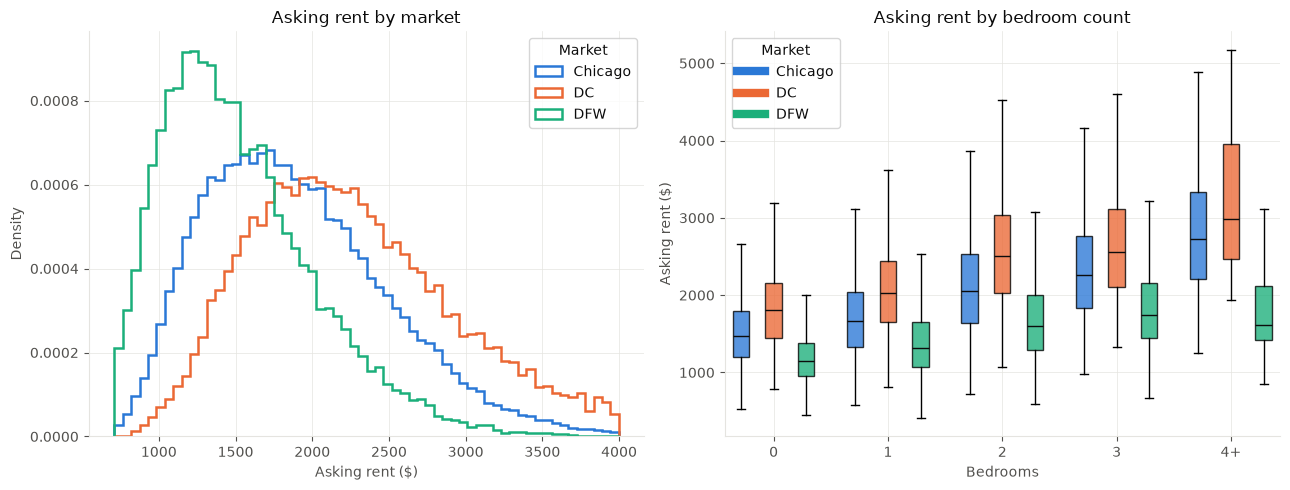

Median asking rent by market:
  Chicago: $1,824
  DC: $2,186
  DFW: $1,429


In [3]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

step("Load candidate variables and target")
funnel_path = upstream(3, "feature_funnel_numerical")
need(funnel_path, "03_numerical_selection")
funnel = pd.read_csv(funnel_path)
candidates_frame = funnel.loc[funnel["x_status"].eq("candidate"), ["variable", "source_table"]]
candidates_frame = candidates_frame.drop_duplicates("variable").reset_index(drop=True)
candidates = candidates_frame["variable"].tolist()
frame = load(candidates + [TARGET, "market", DATE_COLUMN])
frame = frame.dropna(subset=[TARGET]).copy()
done(f"Loaded {len(frame):,} listings with observed asking rent and {len(candidates)} candidates")
if SAMPLE_N is not None and SAMPLE_N < len(frame):
    sample = frame.sample(SAMPLE_N, random_state=SEED)
else:
    sample = frame
markets = sorted(sample["market"].dropna().unique(), key=str)
market_labels = {"chicago": "Chicago", "dc": "DC", "dfw": "DFW"}
market_names = {market: market_labels.get(str(market).lower(), str(market).upper()) for market in markets}
market_palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
market_colors = {market: market_palette[index % len(market_palette)] for index, market in enumerate(markets)}

plt.rcParams.update({
    "text.color": "#0b0b0b",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#e5e4e0",
    "axes.grid": True,
    "grid.color": "#e5e4e0",
    "grid.linewidth": 0.5,
    "axes.axisbelow": True,
})


step("Asking rent distribution")
rent_values = sample[TARGET].dropna()
low, high = rent_values.quantile([0.005, 0.995])
bins = pd.cut(rent_values.clip(lower=low, upper=high), bins=60, retbins=True)[1]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for market in markets:
    # drop the tails instead of clipping them, so they don't pile up as spikes in the edge bins
    values = sample.loc[sample["market"].eq(market), TARGET].dropna()
    values = values[values.between(low, high)]
    axes[0].hist(values, bins=bins, histtype="step", density=True, linewidth=1.8,
                 color=market_colors[market], label=market_names[market])
axes[0].set_xlabel("Asking rent ($)")
axes[0].set_ylabel("Density")
axes[0].set_title("Asking rent by market")
if markets:
    axes[0].legend(title="Market")
style_axes(axes[0])

bed_column = "market_unit__bed"
box_data = []
box_positions = []
box_colors = []
box_ticks = []
position = 1
bedrooms = sample[bed_column].dropna().map(lambda value: "4+" if value >= 4 else str(int(value)))
for group in sorted(bedrooms.unique(), key=lambda value: (value == "4+", int(value.rstrip("+")))):
    group_positions = []
    for market in markets:
        values = sample.loc[bedrooms.eq(group) & sample["market"].eq(market), TARGET].dropna()
        if values.empty:
            continue
        box_data.append(values.to_numpy())
        box_positions.append(position)
        box_colors.append(market_colors[market])
        group_positions.append(position)
        position += 1
    if group_positions:
        box_ticks.append((sum(group_positions) / len(group_positions), group))
        position += 0.5
if box_data:
    artists = axes[1].boxplot(box_data, positions=box_positions, patch_artist=True, showfliers=False,
                              medianprops={"color": "#0b0b0b"})
    for patch, color in zip(artists["boxes"], box_colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.78)
    axes[1].set_xticks([tick[0] for tick in box_ticks], [tick[1] for tick in box_ticks])
axes[1].set_xlabel("Bedrooms")
axes[1].set_ylabel("Asking rent ($)")
axes[1].set_title("Asking rent by bedroom count")
if markets:
    axes[1].legend(handles=[plt.Line2D([0], [0], color=market_colors[market], linewidth=6,
                                       label=market_names[market]) for market in markets],
                   title="Market")
style_axes(axes[1])
fig.tight_layout()
fig.savefig(out("edav_target_distribution", "png"), dpi=150, bbox_inches="tight")
plt.show()
median_rent_by_market = sample.groupby("market")[TARGET].median().to_dict()
print("Median asking rent by market:")
for market in markets:
    print(f"  {market_names[market]}: ${median_rent_by_market[market]:,.0f}")

## 2. Missing values

Each bar gives the share of filtered listings where a candidate value is missing, ordered from highest to lowest. Colors identify the source table, so compare both the percentage and source when deciding which variables may be practical to use.


▶ Candidate missingness


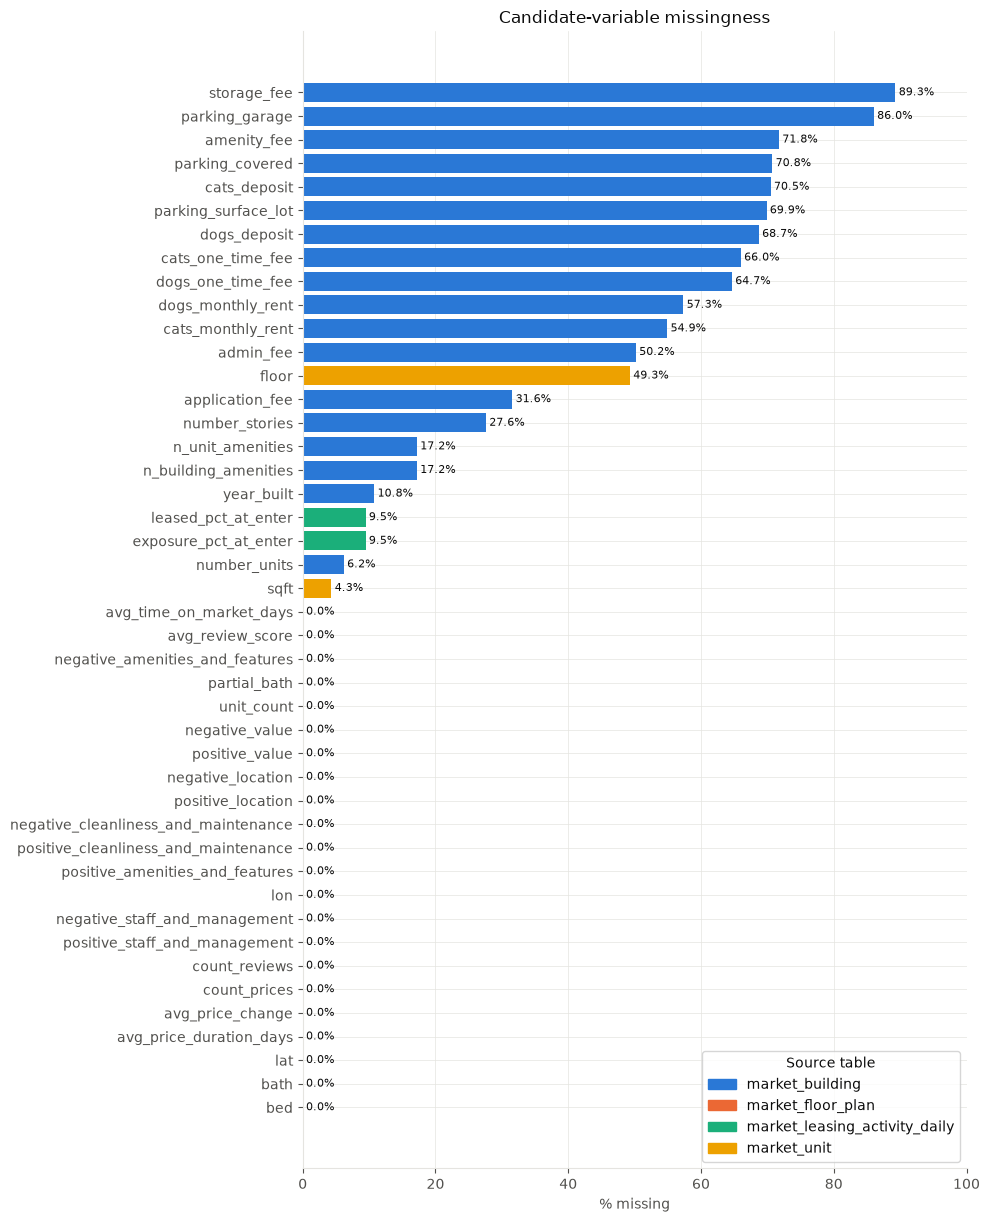

Five most missing:
                        variable missing_pct
    market_building__storage_fee       89.3%
 market_building__parking_garage       86.0%
    market_building__amenity_fee       71.8%
market_building__parking_covered       70.8%
   market_building__cats_deposit       70.5%


In [4]:
step("Candidate missingness")
missingness = candidates_frame.copy()
# all filtered rows, not the plot sample: the count is cheap and exact
missingness["missing_pct"] = [frame[variable].isna().mean() * 100 for variable in candidates]
missingness = missingness.sort_values("missing_pct", ascending=False).reset_index(drop=True)
source_names = sorted(missingness["source_table"].dropna().unique(), key=str)
source_palette = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
source_colors = {name: source_palette[index % len(source_palette)] for index, name in enumerate(source_names)}
fig_height = max(4, 0.28 * len(missingness))
fig, axis = plt.subplots(figsize=(10, fig_height))
bar_colors = [source_colors[source] for source in missingness["source_table"]]
y_positions = range(len(missingness))
axis.barh(list(y_positions), missingness["missing_pct"], color=bar_colors)
axis.set_yticks(list(y_positions), [variable_label(variable) for variable in missingness["variable"]])
axis.invert_yaxis()
axis.set_xlabel("% missing")
axis.set_title("Candidate-variable missingness")
axis.set_xlim(0, max(100, missingness["missing_pct"].max() * 1.12 if len(missingness) else 100))
for y_position, percentage in zip(y_positions, missingness["missing_pct"]):
    axis.text(percentage + 0.5, y_position, f"{percentage:.1f}%", va="center", fontsize=8)
if source_names:
    axis.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=source_colors[name], label=name)
                         for name in source_names], title="Source table", loc="lower right")
style_axes(axis)
fig.tight_layout()
fig.savefig(out("edav_missingness", "png"), dpi=150, bbox_inches="tight")
plt.show()
most_missing = missingness.head(5)[["variable", "missing_pct"]]
print("Five most missing:")
print(most_missing.to_string(index=False, formatters={"missing_pct": "{:.1f}%".format}))

## 3. Per-variable summary and market boxplots

The summary reports completeness, spread, skew, outliers, zeros, and pairwise Spearman association with asking rent for every candidate. The boxplot grid then shows the strongest associated variables, excluding coordinates and variables with fewer than three observed values; market colors are consistent across figures.


▶ Per-variable summary


,variable,source_table,n,missing_pct,median,q1,q3,iqr,skew,outlier_pct,zero_pct,corr_with_target,abs_corr_with_target,median_chicago,median_dc,median_dfw
40,market_building__n_building_amenities,market_building,165571,17.2145,18.0000,18.0000,30.0000,12.0000,-0.1987,0.0000,0.0000,0.5405,0.5405,18.0000,18.0000,18.0000
4,market_unit__sqft,market_unit,191330,4.3350,845.0000,695.0000,1115.0000,420.0000,0.7505,0.5859,0.0000,0.5143,0.5143,855.0000,835.0000,845.0000
41,market_building__n_unit_amenities,market_building,165571,17.2145,14.0000,10.0000,20.0000,10.0000,0.0331,0.0000,0.0000,0.5011,0.5011,14.0000,14.0000,14.0000
23,market_building__parking_surface_lot,market_building,60383,69.8085,40.0000,30.0000,60.0000,30.0000,0.4143,0.0000,0.0000,0.4661,0.4661,40.0000,40.0000,40.0000
18,market_building__amenity_fee,market_building,56319,71.8405,35.0000,25.0000,50.0000,25.0000,0.4896,0.0089,0.0000,0.4515,0.4515,35.0000,30.0000,35.0000
21,market_building__parking_covered,market_building,58541,70.7295,90.0000,65.0000,120.0000,55.0000,0.4811,0.4048,0.0000,0.4504,0.4504,90.0000,95.0000,85.0000
20,market_building__storage_fee,market_building,21382,89.3090,50.0000,35.0000,65.0000,30.0000,-0.0206,0.0000,0.0000,0.4230,0.4230,50.0000,50.0000,50.0000
17,market_building__admin_fee,market_building,99774,50.1130,220.0000,175.0000,295.0000,120.0000,0.4336,0.2736,0.0000,0.4065,0.4065,230.0000,220.0000,205.0000
14,market_building__dogs_monthly_rent,market_building,85316,57.3420,40.0000,30.0000,50.0000,20.0000,0.3027,0.2790,0.0000,0.3990,0.3990,45.0000,40.0000,40.0000
22,market_building__parking_garage,market_building,27749,86.1255,160.0000,115.0000,210.0000,95.0000,0.2796,0.2775,0.0000,0.3828,0.3828,165.0000,160.0000,160.0000



▶ Boxplots by market for top variables


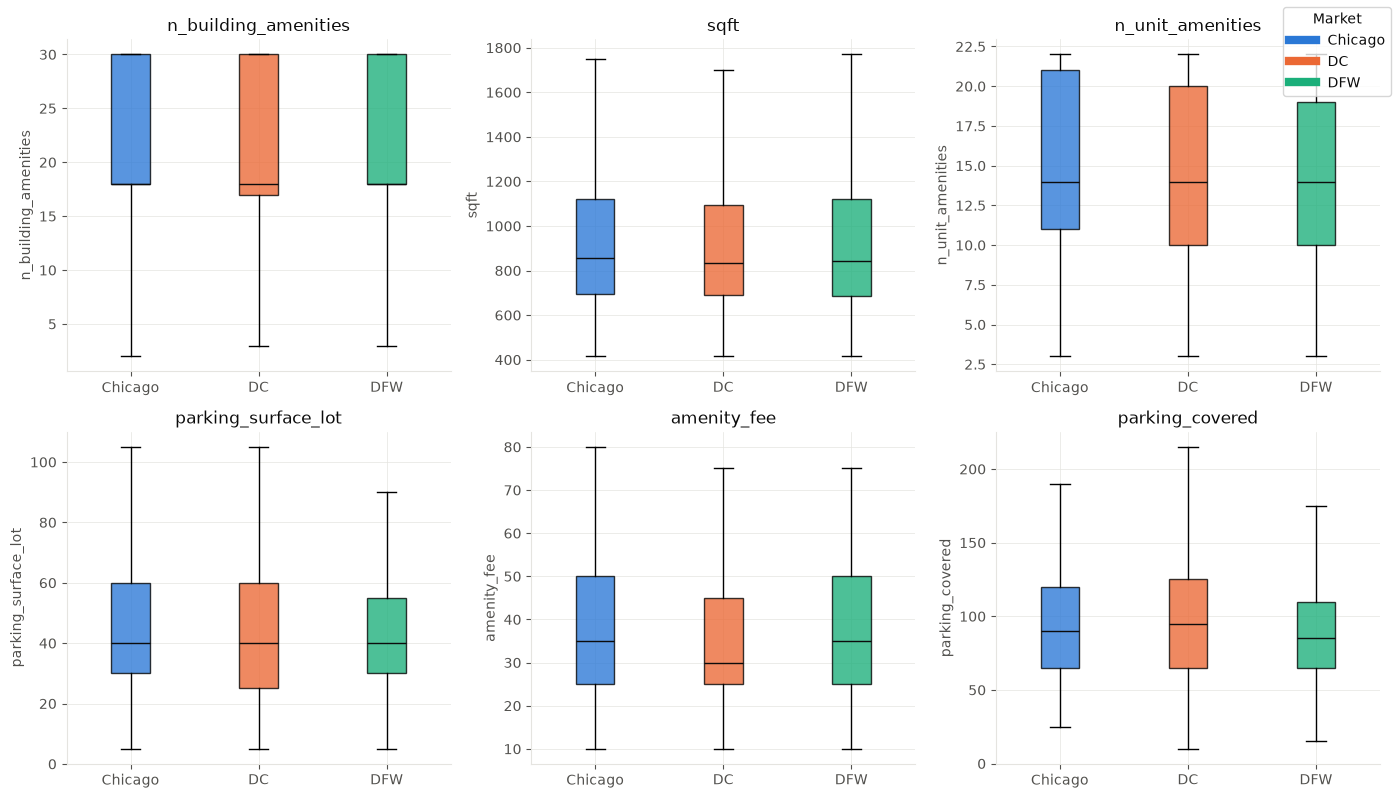

Five most skewed:
                                          variable    skew
                         market_unit__partial_bath  4.6737
                     market_building__count_prices  3.1313
                     market_floor_plan__unit_count  2.9943
market_leasing_activity_daily__leased_pct_at_enter -2.9167
  market_building__positive_amenities_and_features  2.8765


In [5]:
step("Per-variable summary")
summary_rows = []
for row in candidates_frame.itertuples(index=False):
    variable = row.variable
    numeric = pd.to_numeric(sample[variable], errors="coerce")
    valid = numeric.dropna()
    q1 = valid.quantile(0.25)
    median = valid.median()
    q3 = valid.quantile(0.75)
    iqr = q3 - q1
    outside_iqr = (valid < q1 - 1.5 * iqr) | (valid > q3 + 1.5 * iqr)
    outlier_pct = outside_iqr.mean() * 100 if len(valid) else float("nan")
    pair = pd.concat([numeric.rename("x"), sample[TARGET].rename("y")], axis=1).dropna()
    correlation = pair["x"].corr(pair["y"], method="spearman") if len(pair) >= 2 else float("nan")
    result = {
        "variable": variable,
        "source_table": row.source_table,
        "n": int(valid.count()),
        "missing_pct": numeric.isna().mean() * 100,
        "median": median,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "skew": valid.skew() if len(valid) >= 3 else float("nan"),
        "outlier_pct": outlier_pct,
        "zero_pct": (valid.eq(0).mean() * 100) if len(valid) else float("nan"),
        "corr_with_target": correlation,
        "abs_corr_with_target": abs(correlation) if pd.notna(correlation) else float("nan"),
    }
    for market in markets:
        result[f"median_{market}"] = numeric[sample["market"].eq(market)].median()
    summary_rows.append(result)
summary = pd.DataFrame(summary_rows)
summary = summary.sort_values("abs_corr_with_target", ascending=False, na_position="last")
summary = summary.round(4)
summary.to_csv(out("edav_summary"), index=False)
display(summary)
top_candidates = summary.loc[
    ~summary["variable"].isin(NOT_IN_TOP)
    & summary["variable"].map(lambda variable: sample[variable].nunique(dropna=True) >= 3)
].head(TOP_N)
top_variables = top_candidates["variable"].tolist()

step("Boxplots by market for top variables")
columns = 3
rows = max(1, (len(top_variables) + columns - 1) // columns)
fig, axes = plt.subplots(rows, columns, figsize=(14, 4 * rows), squeeze=False)
for index, variable in enumerate(top_variables):
    axis = axes.flat[index]
    box_values = [sample.loc[sample["market"].eq(market), variable].dropna().to_numpy()
                  for market in markets]
    valid_pairs = [(market, values) for market, values in zip(markets, box_values) if len(values)]
    if valid_pairs:
        artists = axis.boxplot([values for _, values in valid_pairs], showfliers=False, patch_artist=True,
                               medianprops={"color": "#0b0b0b"})
        for patch, (market, _) in zip(artists["boxes"], valid_pairs):
            patch.set_facecolor(market_colors[market])
            patch.set_alpha(0.78)
        axis.set_xticks(range(1, len(valid_pairs) + 1), [market_names[market] for market, _ in valid_pairs])
    axis.set_title(variable_label(variable))
    axis.set_ylabel(variable_label(variable))
    style_axes(axis)
for axis in axes.flat[len(top_variables):]:
    axis.set_visible(False)
if markets and top_variables:
    fig.legend(handles=[plt.Line2D([0], [0], color=market_colors[market], linewidth=6,
                                   label=market_names[market]) for market in markets],
               title="Market", loc="upper right")
fig.tight_layout()
fig.savefig(out("edav_boxplots_by_market", "png"), dpi=150, bbox_inches="tight")
plt.show()
most_skewed = summary.assign(abs_skew=summary["skew"].abs()).sort_values(
    "abs_skew", ascending=False, na_position="last").head(5)[["variable", "skew"]]
print("Five most skewed:")
print(most_skewed.to_string(index=False, formatters={"skew": "{:.4f}".format}))

## 4. Asking rent against the top variables

Each panel shows listing density across a candidate and asking rent, with x-values clipped to the central 98% to keep extreme values from compressing the chart. The orange line is the median rent within quantile bins and the title reports the pairwise Spearman correlation.


▶ Asking rent against top variables


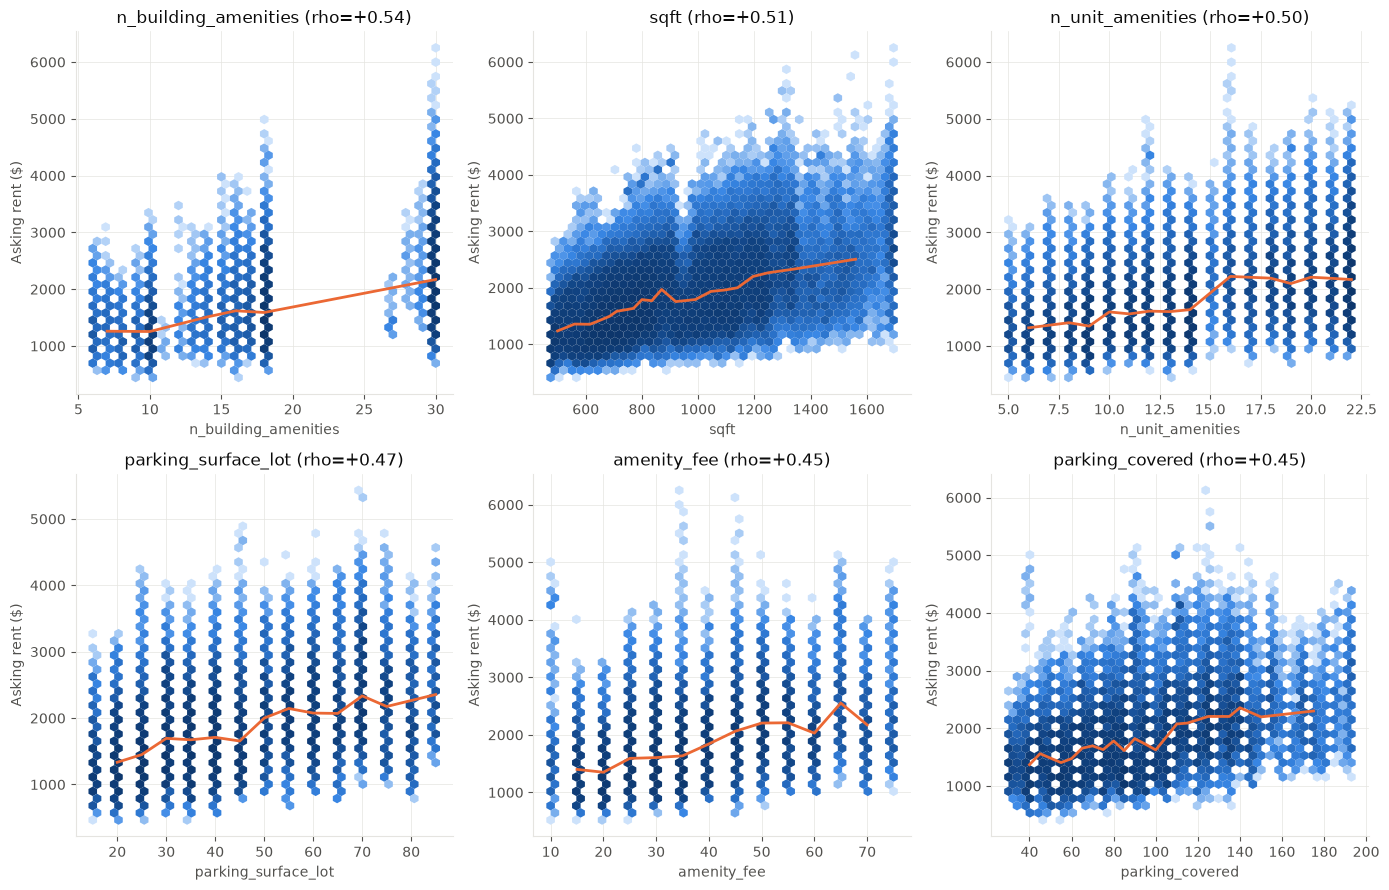

In [6]:
step("Asking rent against top variables")
columns = 3
rows = max(1, (len(top_variables) + columns - 1) // columns)
fig, axes = plt.subplots(rows, columns, figsize=(14, 4.5 * rows), squeeze=False)
sequential = LinearSegmentedColormap.from_list(
    "edav_blues", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281", "#0d366b"]
)
top_correlations = {}
for index, variable in enumerate(top_variables):
    axis = axes.flat[index]
    pair = sample[[variable, TARGET]].apply(pd.to_numeric, errors="coerce").dropna()
    rho = pair[variable].corr(pair[TARGET], method="spearman") if len(pair) >= 2 else float("nan")
    top_correlations[variable] = rho
    if len(pair):
        x_low, x_high = pair[variable].quantile([0.01, 0.99])
        clipped_x = pair[variable].clip(x_low, x_high)
        axis.hexbin(clipped_x, pair[TARGET], gridsize=40, bins="log", mincnt=1,
                    cmap=sequential, linewidths=0)
        if pair[variable].nunique() > 1:
            quantile_bins = pd.qcut(pair[variable], q=20, duplicates="drop")
            median_line = pair.assign(bin=quantile_bins).groupby("bin", observed=True).agg(
                x_median=(variable, "median"), rent_median=(TARGET, "median")
            )
            axis.plot(median_line["x_median"], median_line["rent_median"],
                      color="#eb6834", linewidth=2)
    rho_label = f"{rho:+.2f}" if pd.notna(rho) else "NA"
    axis.set_title(f"{variable_label(variable)} (rho={rho_label})")
    axis.set_xlabel(variable_label(variable))
    axis.set_ylabel("Asking rent ($)")
    style_axes(axis)
for axis in axes.flat[len(top_variables):]:
    axis.set_visible(False)
fig.tight_layout()
fig.savefig(out("edav_rent_vs_top", "png"), dpi=150, bbox_inches="tight")
plt.show()

## 5. Correlation heatmap

This heatmap groups candidate variables with similar absolute correlation patterns using average-linkage clustering. Tile colors preserve the sign and strength of Spearman rho, while the printed pairs identify the strongest relationships without repeating a pair in reverse order.


▶ Candidate correlation heatmap


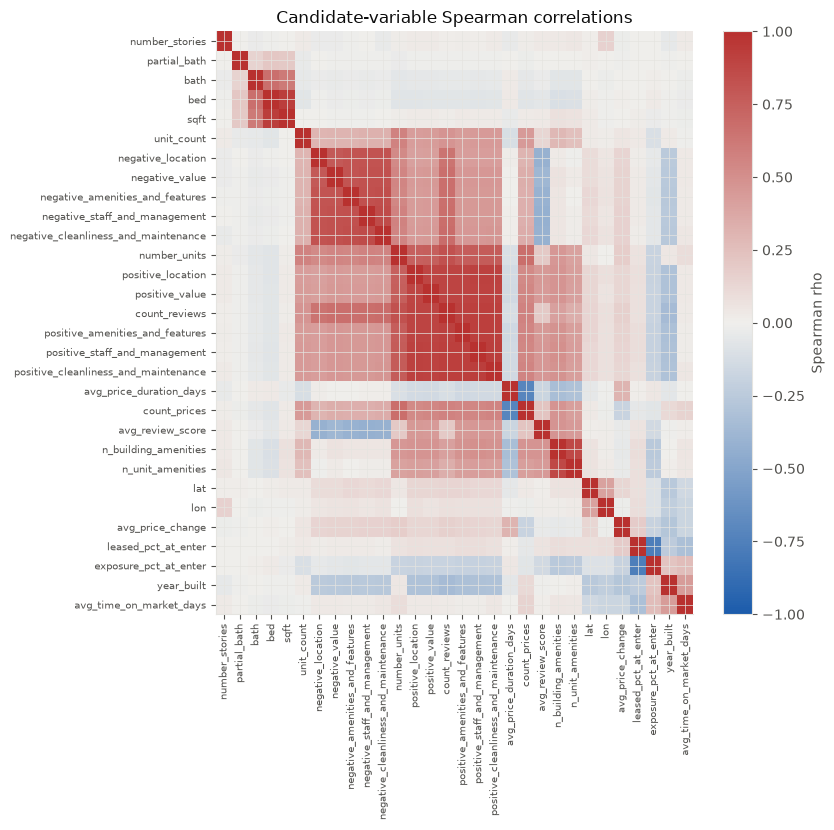

Five strongest candidate pairs:
  positive_staff_and_management / positive_cleanliness_and_maintenance: +0.9286
  bed / sqft: +0.9229
  positive_staff_and_management / positive_amenities_and_features: +0.9202
  positive_amenities_and_features / positive_cleanliness_and_maintenance: +0.9198
  count_reviews / positive_cleanliness_and_maintenance: +0.9165


In [7]:
step("Candidate correlation heatmap")
correlation_path = upstream(4, "correlations_numerical")
need(correlation_path, "04_numerical_correlations")
correlation_matrix = pd.read_csv(correlation_path, index_col="variable")
heatmap_variables = [variable for variable in candidates if variable in correlation_matrix.index
                     and variable in correlation_matrix.columns]
heatmap = correlation_matrix.loc[heatmap_variables, heatmap_variables].apply(
    pd.to_numeric, errors="coerce"
)
ordering_values = heatmap.fillna(0)
if len(heatmap_variables) > 1:
    from scipy.cluster.hierarchy import leaves_list, linkage
    from scipy.spatial.distance import squareform

    distances = (1 - ordering_values.abs()).clip(lower=0, upper=1)
    distances = (distances + distances.T) / 2
    ordered_positions = leaves_list(linkage(squareform(distances.to_numpy(), checks=False),
                                             method="average"))
    ordered_variables = [heatmap_variables[index] for index in ordered_positions]
else:
    ordered_variables = heatmap_variables
ordered_heatmap = heatmap.loc[ordered_variables, ordered_variables]
diverging = LinearSegmentedColormap.from_list(
    "edav_correlation", ["#1c5cab", "#f0efec", "#b8312f"]
)
fig_size = max(7, min(18, 0.28 * len(ordered_variables)))
fig, axis = plt.subplots(figsize=(fig_size, fig_size))
image = axis.imshow(ordered_heatmap.to_numpy(), cmap=diverging, vmin=-1, vmax=1, aspect="auto")
labels = [variable_label(variable) for variable in ordered_variables]
axis.set_xticks(range(len(labels)), labels, rotation=90, fontsize=7)
axis.set_yticks(range(len(labels)), labels, fontsize=7)
axis.set_title("Candidate-variable Spearman correlations")
colorbar = fig.colorbar(image, ax=axis)
colorbar.set_label("Spearman rho")
style_axes(axis)
fig.tight_layout()
fig.savefig(out("edav_correlation_heatmap", "png"), dpi=150, bbox_inches="tight")
plt.show()
correlation_pairs = []
for first_index, first in enumerate(heatmap_variables):
    for second in heatmap_variables[first_index + 1:]:
        rho = heatmap.loc[first, second]
        if pd.notna(rho):
            correlation_pairs.append((first, second, float(rho)))
strongest_pairs = sorted(correlation_pairs, key=lambda pair: abs(pair[2]), reverse=True)[:5]
print("Five strongest candidate pairs:")
for first, second, rho in strongest_pairs:
    print(f"  {variable_label(first)} / {variable_label(second)}: {rho:+.4f}")

## 6. Monthly median asking rent

The upper panel tracks monthly median asking rent and the lower panel tracks listing counts, using the full filtered frame because monthly aggregation is inexpensive. A market-month is shown only when it contains at least 50 listings; the printed change compares the first and last retained monthly medians.


▶ Monthly median asking rent


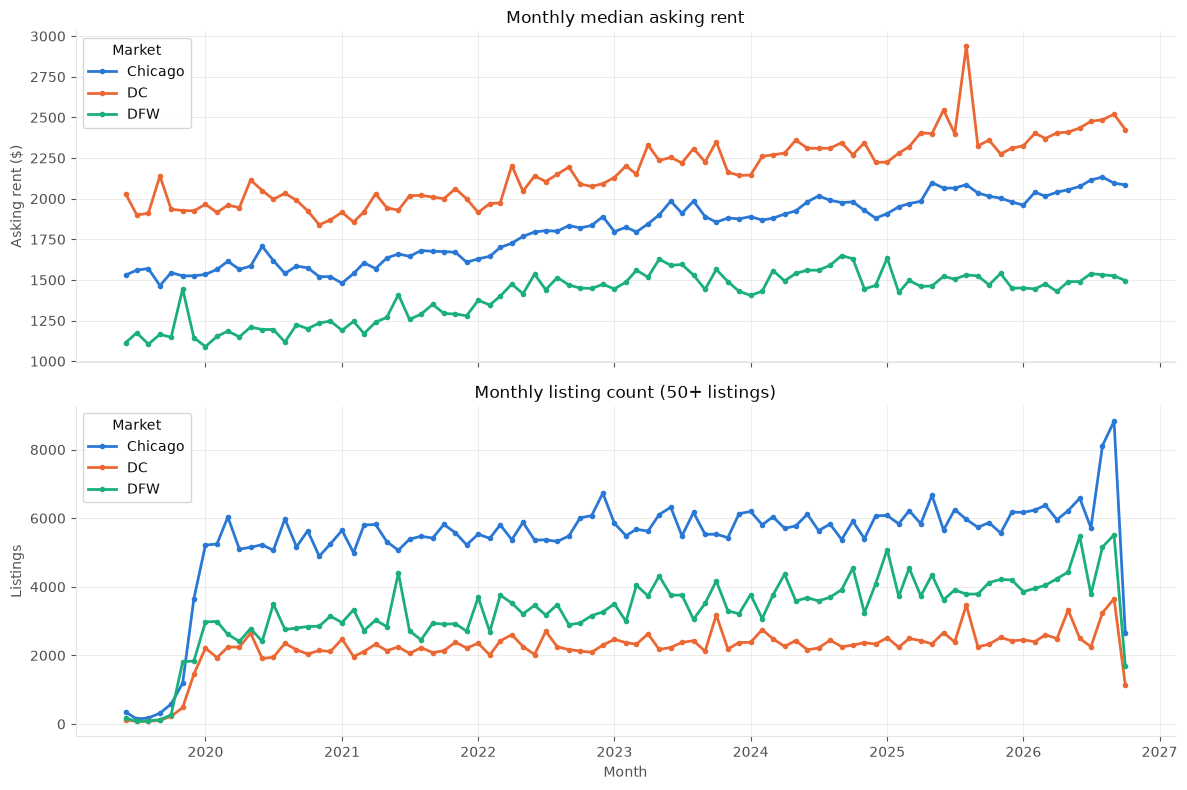

First-to-last retained monthly median rent:
  Chicago: 2019-06 $1,530 → 2026-10 $2,085 (+36.3%)
  DC: 2019-06 $2,030 → 2026-10 $2,425 (+19.5%)
  DFW: 2019-06 $1,114 → 2026-10 $1,496 (+34.3%)


In [8]:
step("Monthly median asking rent")
monthly_frame = frame[[DATE_COLUMN, TARGET, "market"]].dropna(subset=[DATE_COLUMN, TARGET, "market"]).copy()
monthly_frame["month"] = pd.to_datetime(monthly_frame[DATE_COLUMN]).dt.to_period("M").dt.to_timestamp()
monthly = monthly_frame.groupby(["market", "month"], observed=True).agg(
    median_rent=(TARGET, "median"), listing_count=(TARGET, "size")
).reset_index()
monthly = monthly.loc[monthly["listing_count"].ge(50)]
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for market in sorted(monthly["market"].unique(), key=str):
    market_data = monthly.loc[monthly["market"].eq(market)].sort_values("month")
    if market_data.empty:
        continue
    axes[0].plot(market_data["month"], market_data["median_rent"], marker="o", linewidth=2,
                 markersize=3, color=market_colors.get(market, market_palette[0]),
                 label=market_names.get(market, str(market).upper()))
    axes[1].plot(market_data["month"], market_data["listing_count"], marker="o", linewidth=2,
                 markersize=3, color=market_colors.get(market, market_palette[0]),
                 label=market_names.get(market, str(market).upper()))
axes[0].set_ylabel("Asking rent ($)")
axes[0].set_title("Monthly median asking rent")
axes[1].set_ylabel("Listings")
axes[1].set_xlabel("Month")
axes[1].set_title("Monthly listing count (50+ listings)")
for axis in axes:
    if monthly["market"].nunique() > 1:
        axis.legend(title="Market")
    style_axes(axis)
fig.tight_layout()
fig.savefig(out("edav_monthly_rent", "png"), dpi=150, bbox_inches="tight")
plt.show()
monthly_changes = {}
print("First-to-last retained monthly median rent:")
for market in sorted(monthly["market"].unique(), key=str):
    market_data = monthly.loc[monthly["market"].eq(market)].sort_values("month")
    if market_data.empty:
        continue
    first = market_data.iloc[0]
    last = market_data.iloc[-1]
    if first["median_rent"]:
        change_pct = (last["median_rent"] / first["median_rent"] - 1) * 100
    else:
        change_pct = float("nan")
    monthly_changes[market] = change_pct
    market_name = market_names.get(market, str(market).upper())
    first_month = first["month"].strftime("%Y-%m")
    last_month = last["month"].strftime("%Y-%m")
    print(f"  {market_name}: {first_month} ${first['median_rent']:,.0f} → "
          f"{last_month} ${last['median_rent']:,.0f} ({change_pct:+.1f}%)")

## 7. Key numbers

This compact recap gathers the main printed results above for copying into a report. Correlations are shown with their signs, and rent changes compare the first and last months that passed the listing-count threshold.

In [9]:
step("Key numbers for reporting")
print("Median asking rent by market:")
for market in markets:
    print(f"  {market_names[market]}: ${median_rent_by_market[market]:,.0f}")
print("Monthly median-rent change:")
for market, change_pct in monthly_changes.items():
    print(f"  {market_names.get(market, str(market).upper())}: {change_pct:+.1f}%")
print("Five most missing:")
print(most_missing.to_string(index=False, formatters={"missing_pct": "{:.1f}%".format}))
print("Five most skewed:")
print(most_skewed.to_string(index=False, formatters={"skew": "{:.4f}".format}))
print("Top variables and Spearman rho:")
for variable in top_variables:
    rho = top_correlations.get(variable, float("nan"))
    print(f"  {variable_label(variable)}: {rho:+.4f}" if pd.notna(rho)
          else f"  {variable_label(variable)}: NA")
print("Five strongest candidate pairs:")
for first, second, rho in strongest_pairs:
    print(f"  {variable_label(first)} / {variable_label(second)}: {rho:+.4f}")


▶ Key numbers for reporting
Median asking rent by market:
  Chicago: $1,824
  DC: $2,186
  DFW: $1,429
Monthly median-rent change:
  Chicago: +36.3%
  DC: +19.5%
  DFW: +34.3%
Five most missing:
                        variable missing_pct
    market_building__storage_fee       89.3%
 market_building__parking_garage       86.0%
    market_building__amenity_fee       71.8%
market_building__parking_covered       70.8%
   market_building__cats_deposit       70.5%
Five most skewed:
                                          variable    skew
                         market_unit__partial_bath  4.6737
                     market_building__count_prices  3.1313
                     market_floor_plan__unit_count  2.9943
market_leasing_activity_daily__leased_pct_at_enter -2.9167
  market_building__positive_amenities_and_features  2.8765
Top variables and Spearman rho:
  n_building_amenities: +0.5405
  sqft: +0.5143
  n_unit_amenities: +0.5011
  parking_surface_lot: +0.4661
  amenity_fee: +0.4515


## 8. How to read this

These results come from synthetic data and check the method. Rerun this notebook on the real data after rebuilding the master table and rerunning notebooks 02 to 04.